Original Dataset Shape: (178, 13)

Explained Variance Ratio:
[0.362 0.192 0.111 0.071 0.066 0.049 0.042 0.027 0.022 0.019 0.017 0.013
 0.008]


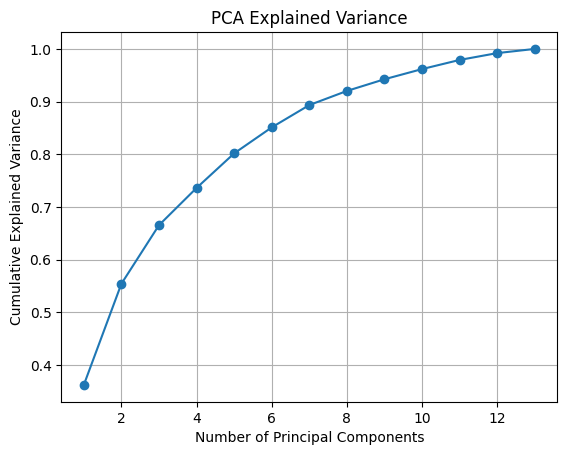


Original Features: 13
Reduced Features: 2


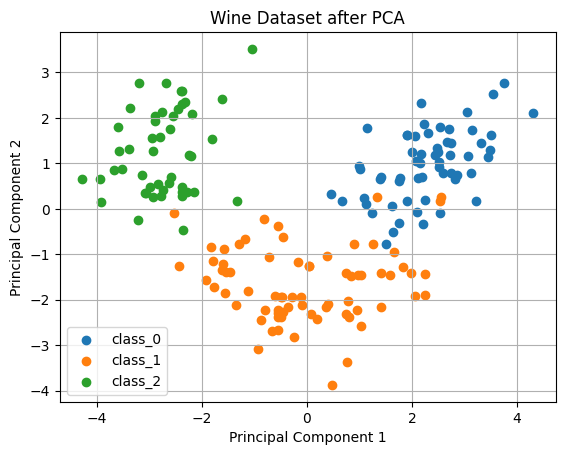


--- Accuracy Comparison ---
Original Data (13 features): 97.22 %
PCA Reduced Data (2 features): 91.67 %


In [3]:

import matplotlib.pyplot as plt
from sklearn.datasets import load_wine
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

# 1. Load dataset
data = load_wine()
X = data.data
y = data.target

print("Original Dataset Shape:", X.shape)

# 2. Feature scaling
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# 3. Apply PCA and calculate explained variance
pca = PCA()
pca.fit(X_scaled)

print("\nExplained Variance Ratio:")
print(pca.explained_variance_ratio_.round(3))

# 4. Plot cumulative explained variance
plt.plot(
    range(1, 14),
    pca.explained_variance_ratio_.cumsum(),
    marker="o"
)
plt.xlabel("Number of Principal Components")
plt.ylabel("Cumulative Explained Variance")
plt.title("PCA Explained Variance")
plt.grid()
plt.show()

# 5. Reduce features to 2 components
pca2 = PCA(n_components=2)
X_2d = pca2.fit_transform(X_scaled)

print("\nOriginal Features:", X.shape[1])
print("Reduced Features:", X_2d.shape[1])

# 6. Visualize data in 2D
for i, name in enumerate(data.target_names):
    plt.scatter(
        X_2d[y == i, 0],
        X_2d[y == i, 1],
        label=name
    )

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("Wine Dataset after PCA")
plt.legend()
plt.grid()
plt.show()

# 7. Split data for accuracy comparison
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# 8. Scale training and testing data
scaler2 = StandardScaler()
X_train_scaled = scaler2.fit_transform(X_train)
X_test_scaled = scaler2.transform(X_test)

# 9. Train Logistic Regression on original features
model1 = LogisticRegression(max_iter=5000)
model1.fit(X_train_scaled, y_train)

pred1 = model1.predict(X_test_scaled)
acc1 = accuracy_score(y_test, pred1)

# 10. Apply PCA using training data only
pca3 = PCA(n_components=2)
X_train_pca = pca3.fit_transform(X_train_scaled)
X_test_pca = pca3.transform(X_test_scaled)

# Train Logistic Regression on reduced features
model2 = LogisticRegression(max_iter=5000)
model2.fit(X_train_pca, y_train)

pred2 = model2.predict(X_test_pca)
acc2 = accuracy_score(y_test, pred2)

# 11. Compare accuracy
print("\n--- Accuracy Comparison ---")
print("Original Data (13 features):", round(acc1 * 100, 2), "%")
print("PCA Reduced Data (2 features):", round(acc2 * 100, 2), "%")
